# 05 - Random Forest

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test Random Forest on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** Random Forest builds many decision trees, each on a random part of the data, and lets them vote. The class with the most votes wins. Because many trees vote together, it makes fewer mistakes than a single tree, and it does not need scaling.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

We try different numbers of trees, tree depths and the smallest number of URLs allowed in a leaf. That gives 8 combinations. Random Forest is slower on 188,000 rows, so we tune on a sample of 50,000 rows. The final model is still trained on the full training set.

In [3]:
MODEL_NAME = "Random Forest"
model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 5],
}

TUNING_SAMPLE_SIZE = 50000

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best cross-validation F1: 1.0000


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,1.0000,0.0001
Precision,1.0000,0.0000
Recall,0.9999,0.0001
F1,1.0000,0.0001
ROC-AUC,1.0000,0.0000


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 5.9 seconds


,Test Score
Accuracy,1.0
Precision,1.0
Recall,1.0
F1,1.0
ROC-AUC,1.0


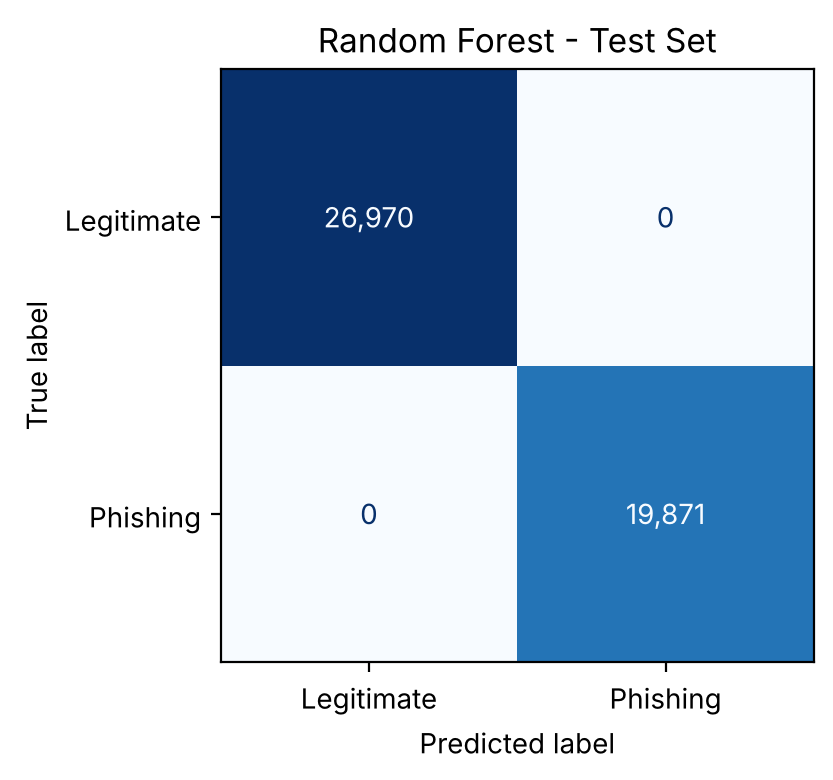

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Importance

Tree models can tell us which features they used most to make decisions. We show the 15 most important features.

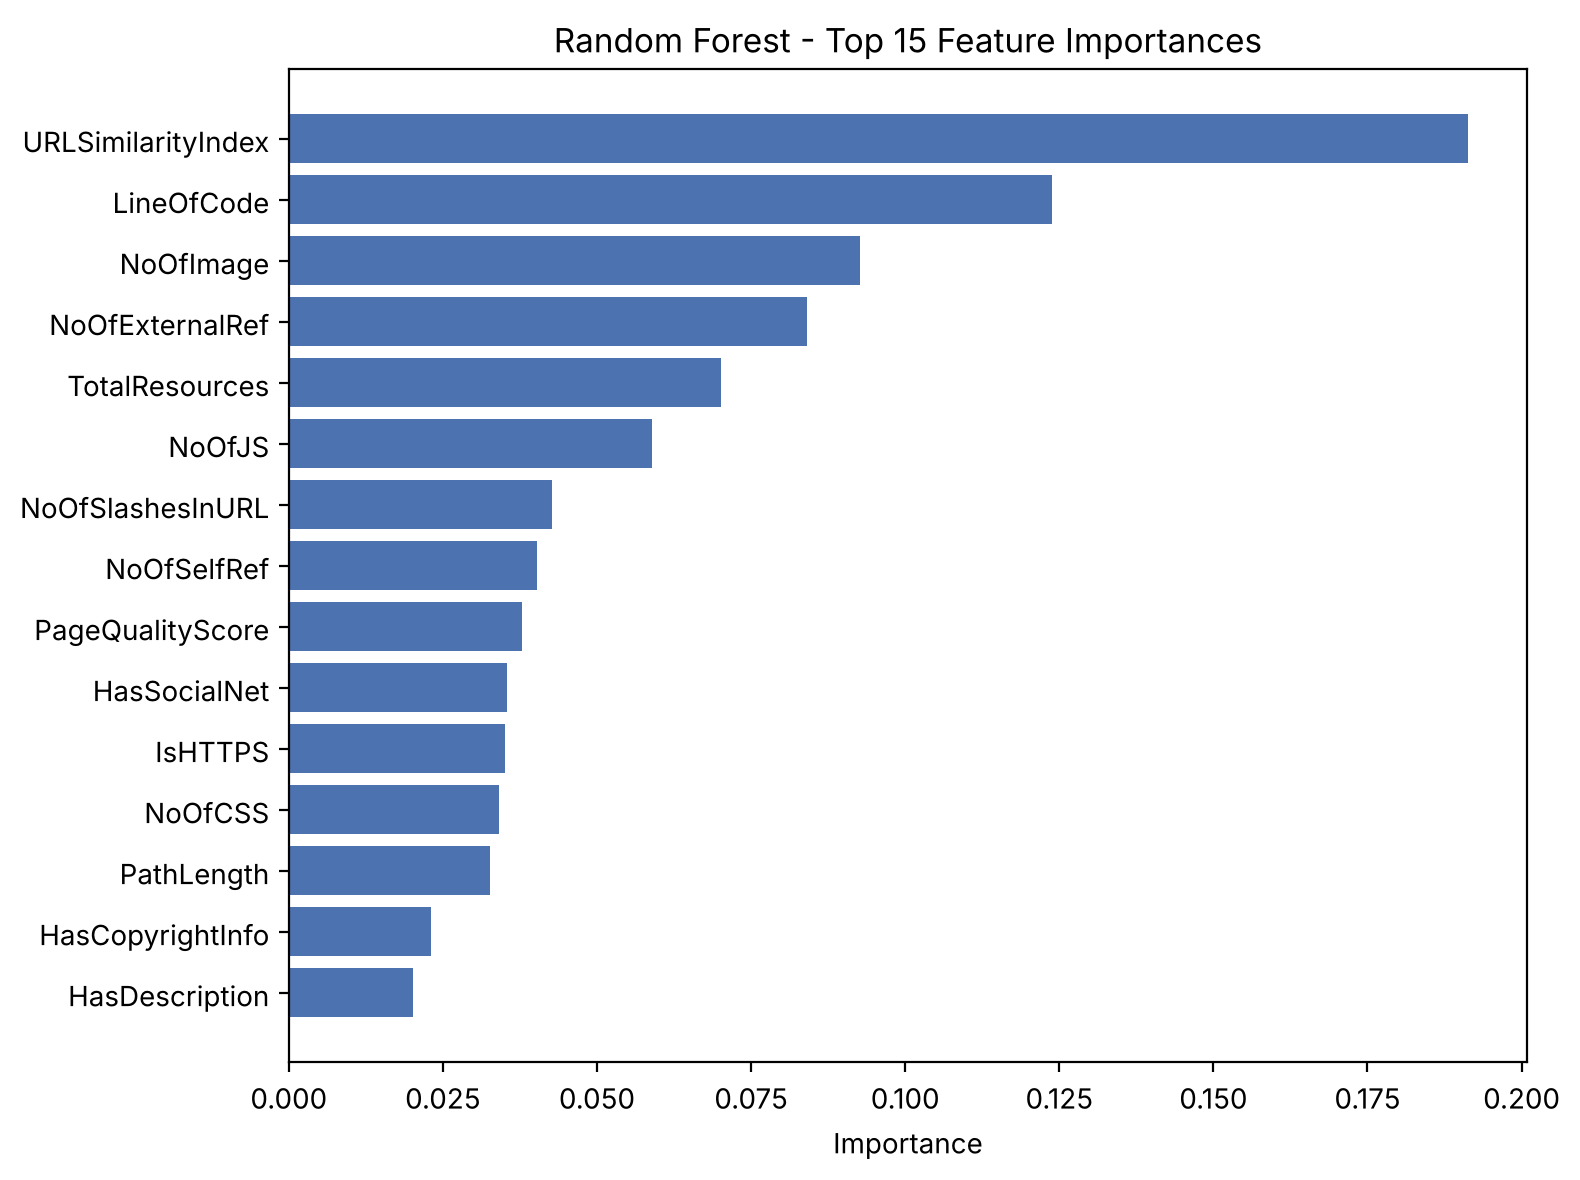

,Importance
URLSimilarityIndex,0.1913
LineOfCode,0.1239
NoOfImage,0.0926
NoOfExternalRef,0.0840
TotalResources,0.0702
NoOfJS,0.0588
NoOfSlashesInURL,0.0427
NoOfSelfRef,0.0402
PageQualityScore,0.0378
HasSocialNet,0.0355


In [8]:
importance = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top_features = importance.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color="#4C72B0")
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "random_forest_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Importance")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,1.0000,1.0000,1.0000,1.0000,1.0
Original features only,1.0000,1.0000,0.9999,0.9999,1.0
Without URLSimilarityIndex,0.9999,0.9999,0.9999,0.9999,1.0


## 5. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [10]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Random Forest,Cross-validation,1.0000,1.0000,0.9999,1.0000,1.0,NaN
1,Random Forest,Test set - All features,1.0000,1.0000,1.0000,1.0000,1.0,5.9476
2,Random Forest,Test set - Original features only,1.0000,1.0000,0.9999,0.9999,1.0,NaN
3,Random Forest,Test set - Without URLSimilarityIndex,0.9999,0.9999,0.9999,0.9999,1.0,NaN


## 6. Findings

- **Test score:** Random Forest made **no mistakes on the 46,841 test URLs** (accuracy 100%). Every phishing URL and every legitimate URL was classified correctly.
- **Stability:** The 5-fold cross-validation scores were almost the same in every fold (standard deviation 0.0001 or less), so the result is stable.
- **Best settings:** 100 trees, no depth limit and `min_samples_leaf = 1`. The model could grow full trees without losing accuracy on new data, because many trees voting together reduce overfitting.
- **Feature importance:** Unlike XGBoost, Random Forest spreads its decisions over many features. `URLSimilarityIndex` is still the most important (19%), followed by page features such as `LineOfCode` (12%), `NoOfImage` (9%), `NoOfExternalRef` (8%) and `TotalResources` (7%, one of our new features). Our new features `TotalResources`, `NoOfSlashesInURL` and `PageQualityScore` are all in the top 10.
- **New features:** With only the original features, the model made 2 mistakes instead of 0. This is a very small gain, but it shows our new features add a little extra information.
- **Without `URLSimilarityIndex`:** The model made only 3 mistakes (accuracy 99.99%). Because Random Forest uses many features, it does not depend on any single one.